# Theoretical Foundations of Computer Science II COMP2870

**School of Computer Science, University of Leeds**

## Lab06: Plots, generating random data and the Central Limit Theorem

On-time submission date: no submission

This worksheet contains only *formative activities* (which contribute to your learning).

**Feedback:** Feedback on formative activities will be provided via tutorials. Feedback on evidence submitted as part of the portfolio will be available on Gradescope.

**Support opportunities:** Support with the activity sheet is available in the lab classes and tutorials. Individual support is available via the maths lunch hours or by contacting the lecturer by email.

**Statement on the Use of Generative AI:**
The aim of this task is for you to develop and demonstrate the specific skills and knowledge covered in the taught sessions. We want you to independently develop and demonstrate your understanding, critical thinking and other fundamental skills that will be required throughout your programme. Reliance on GenAI could **prevent you from achieving** the intended learning outcomes and may **impede your skill development**.

You are permitted to use dictionaries, thesauri, spelling and grammar-checking software to help identify and correct spelling mistakes and grammatical errors (even if they are powered by Gen AI).

**Expected time for completion:** 1-2 hours

## Summary

These lab exercises cover material on how to draw basic bar charts and histograms, how to compute random numbers, and illustrate the distribution of the sample mean in large distributions, including the Central Limit Theorem.

## How to access the lab

You can access the lab worksheet directly through [minerva](https://minerva.leeds.ac.uk/) or using Noteable (accessible via Minerva - see `README.md` for detailed instructions).

These lab worksheets are written using ['Jupyter Notebooks'](https://jupyter.org/). Many, many tutorials and guides are [available online](https://www.dataquest.io/blog/jupyter-notebook-tutorial/).

<div class="alert alert-block alert-danger">
<b>Portfolio exercise</b>

There are no portfolio exercises in this lab worksheet.
</div>

## Exercise 1:

In the first exercise, we will see how to compute basic bar charts and histograms. We use `matplotlib` to provide low-level commands and access them through `pandas` which provides an easier interface. `pandas` provides a dataframe object, which is essentially a table structure: rows correspond to data items and columns correspond to attributes. 


In [1]:
import matplotlib.pyplot as plt 
import pandas as pd
# Eggs.csv contains data with the price of boxes of 12 eggs from several cities around the world. 
# I obtained this from www.numbeo.com where lots of similar data is available. 
df = pd.read_csv("csv/dozenLargeEggs5.csv") # uploads a .csv fle into a dataframe

print(df.head()) # df.head() returns the first 5 rows of the dataframe - good for checking everything looks ok and seeing the column labels

print(f"max = {df['Price'].max()}; min = {df['Price'].min()}; no. rows={df.shape[0]}")

# To access a column of a dataframe df with label 'name' we use df['name'], and then there are many methods that we can apply


   Rank                         City  Price
0     1  Honolulu, HI, United States   6.69
1     2          Zurich, Switzerland   6.26
2     3        San Juan, Puerto Rico   6.04
3     4            Bern, Switzerland   6.02
4     5          Geneva, Switzerland   6.02
max = 6.69; min = 0.63; no. rows=589


To plot a histogram of data in column 'name' of dataframe `df`, we apply the `plot.hist()` method to `df['Name']`.

The `ax=` in the first line of the following code is not necessary to draw the histogram. It returns an `axes` object which allows us to access some of the low level commands of `matplotlib`.

There are many optional arguments to `plot.hist()`. The `bins` argument is the numbers of bars in the histogram, and the `range` argument describes the values that these bars should cover. Using this approach, the bars always have equal width. You can also set `bins` to be equal to a list specifying the boundary of the bars.

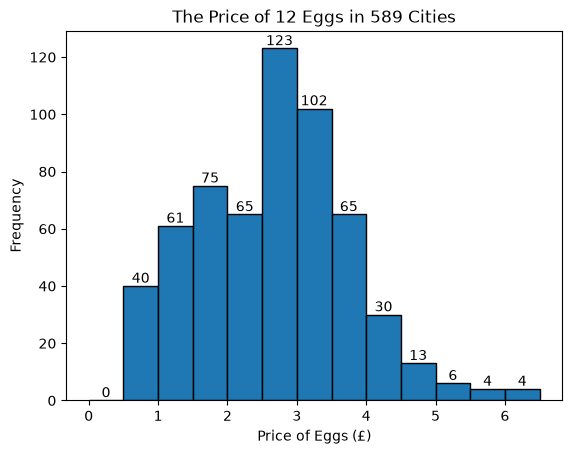

In [2]:
ax=df['Price'].plot.hist(range=(0,6.5), bins=13,edgecolor='black')  
ax.bar_label(ax.containers[0], label_type='edge') # labels the bars of the histogram with the corresponding frequencies.
plt.xlabel("Price of Eggs (£)")
plt.ylabel("Frequency")
plt.title("The Price of 12 Eggs in 589 Cities")
plt.show() # displays the histogram

Next we produce a simple bar chart, although we will only use histograms in the remaining exercises.

The file `emails.csv` comes from [The Data And Story Library](https://dasl.datadescription.com/) and describes the number of emails a statistics lecturer (definitely not me!) received from students who emailed them at least once. Each line of the dataframe corresponds to a student and the only entry in each row is equal to the number of emails that they sent.

In [3]:
df = pd.read_csv("csv/emails.csv")
print(df.head())
print(f"max = {df['Number_of_E-mails'].max()}; min = {df['Number_of_E-mails'].min()}; no. rows={df['Number_of_E-mails'].shape[0]}")


   Number_of_E-mails
0                  1
1                  2
2                  1
3                  4
4                  1
max = 21; min = 1; no. rows=155


The `value-counts()` method gives the frequency distribution of a column of a dataframe. It arranges the frequency distribution in decreasing order of frequencies, but to draw a bar chart with the bars in a sensible order, we need to sort on the data values. 

Try removing `.sort_index()` below and see what happens.

In [8]:
df['Number_of_E-mails'].value_counts().sort_index()

Number_of_E-mails
1     80
2     41
3     16
4      7
5      5
8      2
6      2
21     1
7      1
Name: count, dtype: int64

To draw the bar chart we use the `plot.bar()` method. By default the labels on the x-axis are displayed rotated by 90 degrees, because typically they are too long to write horizontally. The line `plt.xticks(rotation=0)` ensures that the labels on the x-axis are not rotated.

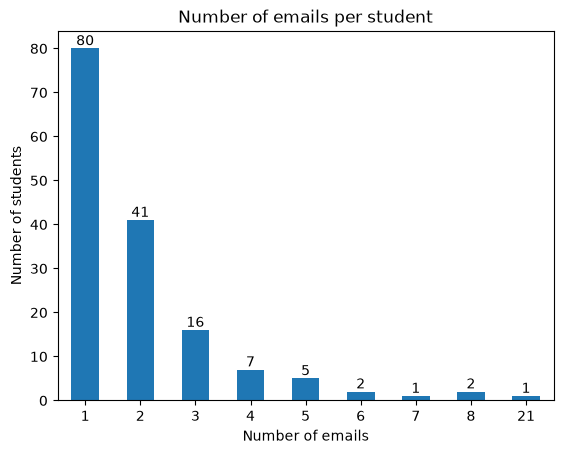

In [11]:
ax=df['Number_of_E-mails'].value_counts().sort_index().plot.bar()
ax.bar_label(ax.containers[0], label_type='edge')
plt.title("Number of emails per student")
plt.xticks(rotation=0)
plt.xlabel("Number of emails")
plt.ylabel("Number of students")
plt.show()

## Exercise 2:

In the rest of the exercises you are going to generate a large sample of random numbers, each of which is the mean of $n$ random numbers all drawn from the same distribution, and compare how things change as $n$ increases.

a) Create a list of 1000 random numbers all drawn from the standard normal distribution. The function `random.gauss()` from the `random` module returns a random number drawn from the standard normal distribution. Read the list into a dataframe (see below) and draw a histogram of the results using `range=(-3.75,3.75)` and `bins=13`.

b) Now create a list of 1000 random numbers, each of which is the mean of $n=5$ random numbers all drawn from the standard normal distribution. (So generate 5 random numbers from the standard normal distribution and compute their mean, and then repeat until you have done this 1000 times.) Draw a histogram of the results with the same `range` and `bins` as before. Repeat with $n=10$, $n=100$ and $n=1000$. Is the result what you expected? You should see that the numbers get closer to $0$ as $n$ increases. Does this seem sensible?

c) In part b), as $n$ increases, the standard deviation of the numbers in the sample decreases. (This idea is made precise in Lecture 4.) In fact the standard deviation decreases by a factor of $\sqrt{n}$, as $n$ increases. Repeat part b) for each value of $n$, but this time each number in the list should be obtained by taking the mean of $n$ random numbers and then multiplying by $\sqrt{n}$. 

Text(0, 0.5, 'frequency')

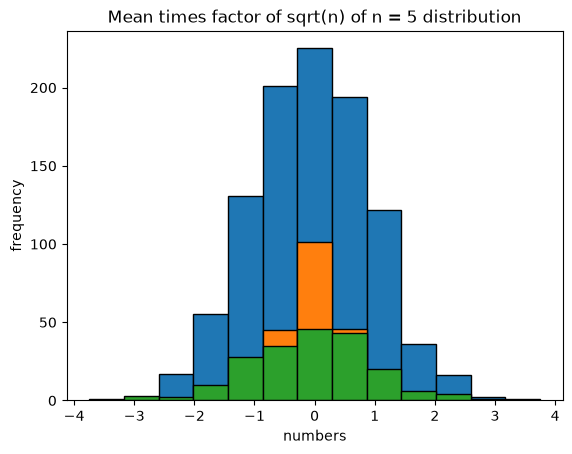

In [46]:
import pandas as pd
import random
import matplotlib.pyplot as plt
import math

# to read one or more lists of numbers into a dataframe called df use 
# rand_nos = pd.DataFrame({'sample-1': sample_1, 'sample-5': sample_5, 'sample-10': sample_10})
# if sample_1, sample_5 and sample_10 are lists, then this will give you a dataframe with 3 columns corresponding to these lists and 
# headings 'sample-1', 'sample-5' and 'sample-10'

# add your code here

# a)


thousand_list = [ random.gauss() for x in range(1000) ]
d = { "Numbers":thousand_list }
df = pd.DataFrame(data=d)
ax = df["Numbers"].plot.hist(range=(-3.75,3.75), bins=13,edgecolor='black')
plt.title("Normal Distribution")
plt.xlabel("numbers")
plt.ylabel("frequency")


# b)


thousand_list = []
mean_list = []
summer = 0

for i in range(1, 1001):
    rand = random.gauss()
    thousand_list.append(rand)

    if i % 5 == 0:
        summer = 0
        for j in range(i-5,i):
            summer += thousand_list[j]
        mean_list.append((summer)/5)

d = { "Numbers":mean_list }
df = pd.DataFrame(data=d)
ax = df["Numbers"].plot.hist(range=(-3.75,3.75), bins=13,edgecolor='black')
plt.title("Mean of n=5 distribution")
plt.xlabel("numbers")
plt.ylabel("frequency")


# c)


thousand_list = []
mean_list = []
summer = 0
n = 5

for i in range(1, 1001):
    rand = random.gauss()
    thousand_list.append(rand)

    if i % 5 == 0:
        summer = 0
        for j in range(i-n,i):
            summer += thousand_list[j]
            
        mean_list.append(((summer)/n)*math.sqrt(n))

d = { "Numbers":mean_list }
df = pd.DataFrame(data=d)
ax = df["Numbers"].plot.hist(range=(-3.75,3.75), bins=13,edgecolor='black')
plt.title("Mean times factor of sqrt(n) of n = 5 distribution")
plt.xlabel("numbers")
plt.ylabel("frequency")

    

## Exercise 3:

The histograms from the last part of the previous exercise should all have the same shape. This is not surprising as normally distributed random variables also have the normal distribution, but remarkably it turns out that if we repeat Exercise 2 with a different starting distribution, then we still end up with the same results in Parts b) and c).

a) Repeat Exercise 2, but start off by generating random numbers from the uniform distribution on $[0,1]$. The function `random.random()` returns a uniformly distributed random number from $U[0,1]$. In order to make the histograms comparable with those from Exercise 2 use the formula `(random.random() - 0.5) * math.sqrt(12)` to generate the random numbers, as this normalizes them so that they have mean $0$ and standard deviation $1$.

b) Repeat Exercise 2, but start off by generating random numbers from the exponential distribution with parameter $1$. The function `random.expovariate(1)` returns a exponentially distributed random number with parameter $1$. In order to make the histograms comparable with those from Exercise 2 use the formula `random.expovariate(1)-1` to generate the random numbers, as this normalizes them to generate the random numbers, as this normalizes them so that they have mean $0$ and standard deviation $1$. 

Text(0, 0.5, 'frequency')

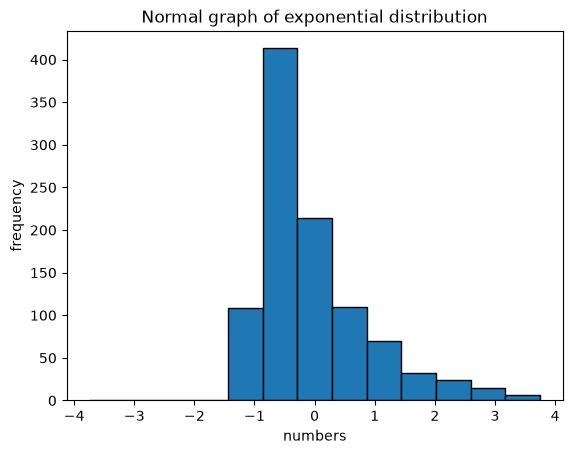

In [57]:
import pandas as pd
import random
import matplotlib.pyplot as plt
import math

# to read one or more lists of numbers into a dataframe called df use 
# rand_nos = pd.DataFrame({'sample-1': sample_1, 'sample-5': sample_5, 'sample-10': sample_10})
# if sample_1, sample_5 and sample_10 are lists, then this will give you a dataframe with 3 columns corresponding to these lists and 
# headings 'sample-1', 'sample-5' and 'sample-10'

# add your code here 

# a)

"""
thousand_list = []
#mean_list = []
summer = 0
n = 10

for i in range(1, 1001):
    rand = (random.random() - 0.5) * math.sqrt(12)
    thousand_list.append(rand)

    ""
    if i % n == 0:
        summer = 0
        for j in range(i-n,i):
            summer += thousand_list[j]
            
        mean_list.append(((summer)/n))
    ""
    
d = { "Numbers":thousand_list }
df = pd.DataFrame(data=d)
ax = df["Numbers"].plot.hist(range=(-3.75,3.75), bins=13,edgecolor='black')
plt.title("Normal graph of uniform distribution [0,1]")
plt.xlabel("numbers")
plt.ylabel("frequency")
"""

# b)


thousand_list = []
#mean_list = []
summer = 0
n = 10

for i in range(1, 1001):
    rand = random.expovariate(1)-1
    thousand_list.append(rand)

    """
    if i % n == 0:
        summer = 0
        for j in range(i-n,i):
            summer += thousand_list[j]
            
        mean_list.append(((summer)/n))
    """

d = { "Numbers":thousand_list }
df = pd.DataFrame(data=d)
ax = df["Numbers"].plot.hist(range=(-3.75,3.75), bins=13,edgecolor='black')
plt.title("Normal graph of exponential distribution")
plt.xlabel("numbers")
plt.ylabel("frequency")



## Exercise 4 (Optional Extension):

a) Write a function to generate a random number from the distribution whose density function is $f(x) = 2x$ if $0 \leq x \leq 1$, and $0$ otherwise. 

b) Repeat Exercise 2 for this distribution




In [ ]:
def rand_mydist():
    # write some code so that rand_no is a random number drawn from the distribution described.
    rand_no = ...
    return rand_no